# AgriScreen: is my vineyard drier than usual?

A winegrower near Condom (Gers, south-west France) wants one simple answer: **is my parcel unusual right now,
compared with its own history?** AgriScreen answers it with open Copernicus data and says how far each answer can be
trusted.

The card for each vineyard has three sentences:

1. **Soil in the area:** dry / near normal / wet (ERA5-Land model, about 9 km, checked against soil sensors).
2. **Your parcel:** the vegetation water index (Sentinel-2, short-wave infrared) below / within / above its own
   normal for this time of year, and how many vineyards nearby are in the same state.
3. **The area:** whether vineyard vegetation follows soil water. This sentence appears only if a pre-registered test
   confirms it. In the first run it did not, so the card hides it.

AgriScreen gives no irrigation advice and does not diagnose vine water stress: the satellite sees the whole parcel,
vines, inter-rows and soil together.

Interactive panel: `docs/showcase/agriscreen_panel.html` · code and protocol:
[github.com/geoworldlook/agriscreen](https://github.com/geoworldlook/agriscreen).

In [1]:
import json, os, re, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data published with the repository (no keys, no Earth Engine, no GPU needed)
DATA = next((p for p in ('docs/showcase', '../docs/showcase', '/content/agriscreen/docs/showcase') if os.path.isdir(p)), None)
if DATA is None and 'google.colab' in sys.modules:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/geoworldlook/agriscreen.git', '/content/agriscreen'], check=True)
    DATA = '/content/agriscreen/docs/showcase'
D = json.load(open(os.path.join(DATA, 'agriscreen_data.json'), encoding='utf-8'))
tests = pd.read_csv(os.path.join(DATA, 'w3b_tests.csv'))
dates = pd.to_datetime(D['dates'])
print(f"{len(D['map']['shapes'])} vineyards, {len(dates)} Sentinel-2 scene days {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}")
print(f"Tests frozen on {D['freeze']}, protocol SHA-256 {D['protocol']}...")
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLORS = {'wb': '#7a4a0e', 'b': '#c08a3e', 'n': '#e9e6dc', 'a': '#5fa69b', 'wa': '#1f6a62', 'nd': '#f4f4f0'}
def zclass(z):
    if z is None or not np.isfinite(z): return 'nd'
    return 'wb' if z <= -1.5 else 'b' if z <= -1 else 'n' if z < 1 else 'a' if z < 1.5 else 'wa'
def layer(key):
    return pd.DataFrame({s: pd.Series(v, index=dates, dtype=float) for s, v in D['layers'][key].items()})
water = layer('water')
qc = [s for s, v in D['sites'].items() if v['qc_ok']]

15 vineyards, 329 Sentinel-2 scene days 2018-04-19 to 2026-10-14
Tests frozen on 2026-10-18, protocol SHA-256 f01b74a804b2...


## 1. Fifteen vineyards, each against its own history

Every vineyard in the study area (15 parcels, 0.7 to 4.1 ha) is measured inside a strip 20 m from its edge, so that
20 m infrared pixels do not mix in the neighbours. Two parcels are too small after that cut (fewer than 40 pixels);
they get no class.

For each scene, the index of a parcel is compared with the **same parcel in the previous five years**, within
±15 days of the calendar and on the same satellite orbit. The result is a z-score: −1 means clearly below its own
normal. The map shows the latest scene.

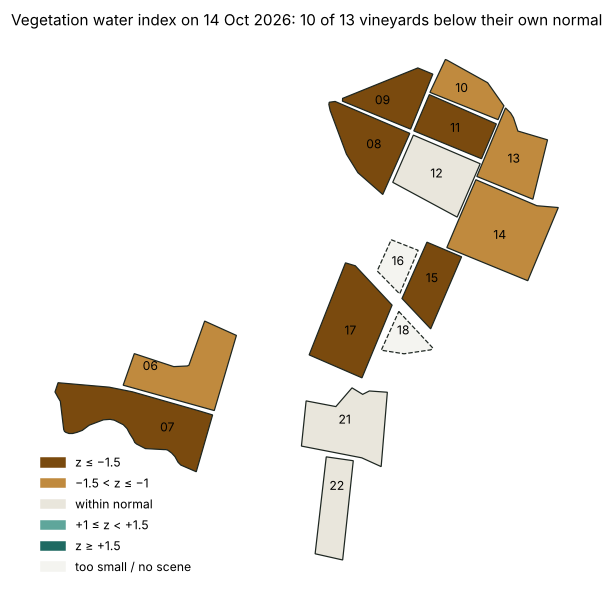

In [2]:
def polys(d):
    return [np.array([[float(a) for a in p.split(',')] for p in part.split('L')]) for part in d.strip('Z').split('ZM')]
last = dates.max()
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for s in D['map']['shapes']:
    z = water.loc[last, s['id']] if s['id'] in water else np.nan
    c = COLORS[zclass(z)] if s['id'] in qc else COLORS['nd']
    for xy in polys(s['d'].lstrip('M')):
        ax.fill(xy[:, 0], -xy[:, 1], color=c, ec='#1d2621', lw=0.8, ls='-' if s['id'] in qc else '--')
    ax.text(s['cx'], -s['cy'], f"{s['fid']:02d}", ha='center', va='center', fontsize=8)
ax.set_aspect('equal'); ax.axis('off')
n = sum(1 for s in qc if water.loc[last, s] <= -1)
ax.set_title(f"Vegetation water index on {last:%d %b %Y}: {n} of {water.loc[last, qc].notna().sum()} vineyards below their own normal", fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORS[k], label=l) for k, l in (('wb', 'z ≤ −1.5'), ('b', '−1.5 < z ≤ −1'), ('n', 'within normal'),
          ('a', '+1 ≤ z < +1.5'), ('wa', 'z ≥ +1.5'), ('nd', 'too small / no scene'))], loc='lower left', fontsize=8, frameon=False)
plt.show()

## 2. Soil water in the area: checked against sensors in the ground

The soil sentence uses the ERA5-Land model (0–100 cm) and the ASCAT soil water index from Copernicus. Both were
validated against soil sensors at three stations: Condom (ISMN, 136 m from vineyard 06), Auradé in the Gers and
Lusignan (ICOS). The protocol was registered before computing. The model agrees with the sensors moderately
(R about 0.6) and puts the day in the same dry/normal/wet class about half the time.

In [3]:
trust = pd.DataFrame(D['trust'])[['what', 'against', 'result', 'status']]
display(trust)

what,against,result,status
"Soil moisture 0–100 cm (ERA5-Land model, ~9 km)","in situ soil sensors at 3 stations (ISMN Condom, ICOS Auradé and Lusignan)","Condom R 0.57; Auradé R 0.57; Lusignan R 0.68; same dry/normal/wet class on 55%, 55%, 65% of days",validated
"Soil water index (ASCAT satellite, ~10 km)","in situ soil sensors at 3 stations (ISMN Condom, ICOS Auradé and Lusignan)","Condom R 0.57; Auradé R 0.52; Lusignan R 0.54; same dry/normal/wet class on 52%, 49%, 60% of days",validated
"Rainfall, 30-day sums (ERA5-Land)","rain gauge CONDOM (0 km, 173 m)",R 0.90,validated
Parcel vegetation water index: noise between scenes,pairs of scenes a few days apart without rain,"smallest clear change: 1.0 z (same orbit), 1.1 z (different orbits)",validated
Parcel index: how often “below its own normal” appears,"all scenes June–September, 13 vineyards (expected 16%, 1 in 6)","28% [4–52%], mostly in dry years; 14% when soil is near normal",validated
Area vegetation follows soil water of the previous 30 days,"ISMN sensor at Condom, June–September 2018–2024 (pre-registered test)","ρ 0.55 [-0.02; 1.00]; mostly between years, not within a season",not confirmed
"4-band model (red, red-edge, NIR, SWIR) instead of the simple index","same test, years unseen by the model",no gain: Δρ -0.01 [-0.18; 0.16],not adopted
Vine water stress,no measurements inside the vineyards,"not assessed; the index sees the whole parcel, vines and inter-rows",not validated


## 3. The parcel index: water in the vegetation

The index averages two short-wave infrared indices that react to water in leaves (NDMI and CRSWIR; Ceccato et al.
2001). It sees the whole parcel, so it moves together with greenness and reacts mostly to stronger deficits.

The seasons below show the main pattern found in the tests: in a wet year (2021) the vineyards stay near their
normal; in the dry year 2022 almost all of them drop below it at the same time. That is why the card also says how
many vineyards nearby are in the same state.

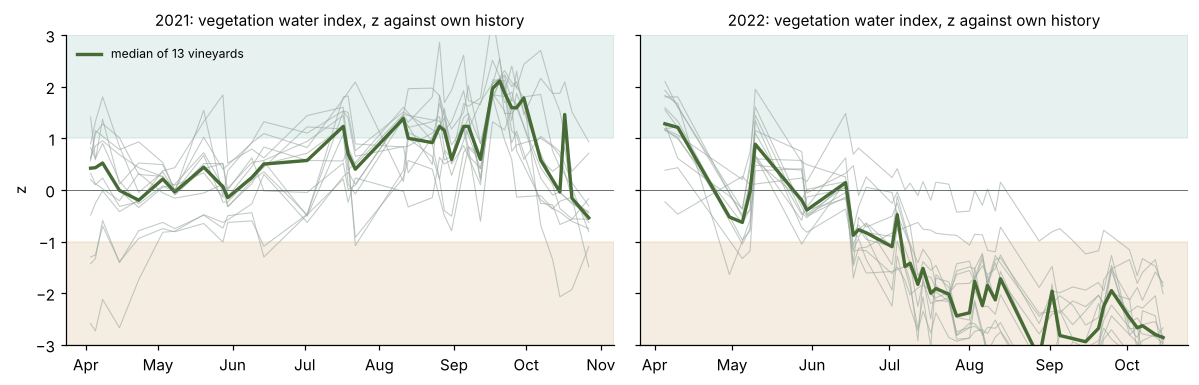

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, year in zip(axes, (2021, 2022)):
    w = water[(water.index.year == year)][qc]
    for s in qc:
        v = w[s].dropna()
        ax.plot(v.index, v.values, color='#9aa89f', lw=0.7, alpha=0.6)
    med = w.median(axis=1).dropna()
    ax.plot(med.index, med.values, color='#466b35', lw=2.2, label='median of 13 vineyards')
    ax.axhspan(-3, -1, color=COLORS['b'], alpha=0.15); ax.axhspan(1, 3, color=COLORS['a'], alpha=0.15)
    ax.axhline(0, color='#5d6a62', lw=0.6); ax.set_ylim(-3, 3)
    ax.set_title(f'{year}: vegetation water index, z against own history', fontsize=10)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b'))
axes[0].set_ylabel('z'); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Pre-registered tests and their results

The rules and the pass criteria were written down and hashed (SHA-256) before any number was computed, so they could
not be tuned after seeing the results. Only two tests decide something; the rest is reported as description.

- **T1 calibration:** how often the class “below its own normal” appears (expected about 16%).
- **T2 noise:** how large a change between two close scenes must be to count as real.
- **T3 (decides sentence 3):** does the median of 12 vineyards follow the soil sensor at Condom over the previous
  30 days? Criterion: the lower bound of a 95% interval (jackknife by year) above zero.
- **4-band model (decides the index):** does a model of red, red-edge, NIR and SWIR bands, trained on the sensor,
  beat the simple index on years it has not seen?

test,value,95% interval,n,years,decides,verdict
"T1 share of “below normal” (13 vineyards, June–Sept.)",0.28,[0.04; 0.52],2469,2018-2026,False,no gross miscalibration
"T2 smallest clear change, same orbit",1.03,[0.59; 1.47],638,2019-2026,False,
"T2 smallest clear change, different orbits",1.12,[0.77; 1.46],799,2019-2026,False,
T3 vegetation vs soil sensor (ρ),0.55,[-0.02; 1.00],140,2018-2024,True,not met (inconclusive)
4-band model gain over the simple index (Δρ),-0.01,[-0.18; 0.16],140,2018-2024,True,not adopted


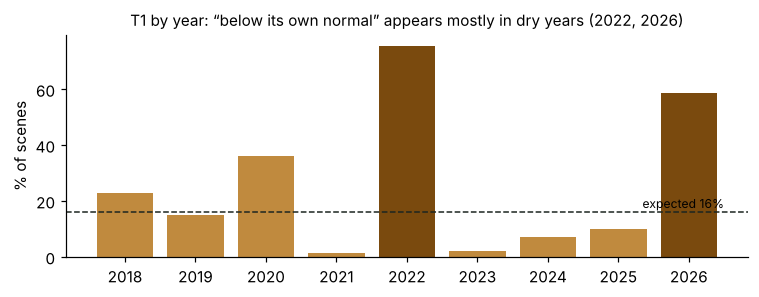

In [5]:
keys = {'t1_main': 'T1 share of “below normal” (13 vineyards, June–Sept.)', 't2_g5': 'T2 smallest clear change, same orbit',
        't2_g13': 'T2 smallest clear change, different orbits', 't3_main': 'T3 vegetation vs soil sensor (ρ)',
        'p7_accept': '4-band model gain over the simple index (Δρ)'}
k = tests[tests['key'].isin(keys)].set_index('key').loc[list(keys)]
res = pd.DataFrame({'test': [keys[i] for i in k.index], 'value': k['value'].round(2), '95% interval': [f"[{a:.2f}; {b:.2f}]" for a, b in zip(k['ci_low'], k['ci_high'])],
                    'n': k['n'], 'years': k['period'], 'decides': k['criterion'], 'verdict': k['verdict'].fillna('')})
res['verdict'] = res['verdict'].replace({'niespełnione (nierozstrzygnięty)': 'not met (inconclusive)', 'nieprzyjęty': 'not adopted',
                                         'nie wykryto grubego rozkalibrowania': 'no gross miscalibration'})
display(res.reset_index(drop=True))
yr = tests[(tests['segment'] == 'T1') & tests['subset'].str.startswith('rok ')]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(yr['subset'].str[4:], 100 * yr['value'], color=['#7a4a0e' if v > 0.4 else '#c08a3e' for v in yr['value']])
ax.axhline(15.9, color='#1d2621', ls='--', lw=1); ax.text(len(yr) - 0.5, 17.5, 'expected 16%', ha='right', fontsize=8)
ax.set_ylabel('% of scenes'); ax.set_title('T1 by year: “below its own normal” appears mostly in dry years (2022, 2026)', fontsize=10)
plt.tight_layout(); plt.show()

## 5. What we learned

- **The parcel index is stable and well calibrated.** A change of about 1 z between two close scenes is real; in
  years with normal soil the class “below its own normal” appears in 14% of scenes, close to the expected 16%.
- **Sentence 3 stays hidden.** Vineyard vegetation and the soil sensor agree mostly between years (ρ of seasonal
  means 0.64) but not within a season (0.06). The main test gave ρ = 0.55 with an interval from −0.02 to 1.00: just
  below the criterion, as the power simulation predicted with only seven seasons.
- **More bands did not help.** The 4-band model did no better than the simple index and failed in the dry year
  2022. It stays as the baseline for a future neural-network unmixing of vines and inter-rows.
- **Earlier numbers were inflated.** A previous experiment compared each scene with all other years, including future
  ones. Fixing that lowered the agreement with the sensor from 0.57 to 0.44 on the same days; better sensor quality
  control brought it back to about 0.5.

The next fair test needs new data: the 2027 season, with the same registered rules.

In [6]:
c = D['cards'][D['main_site']]
print(f"Card for vineyard 06, latest scene {c['date']}:")
for i, s in enumerate(c['sentences'], 1):
    print(f'  {i}. {s}')
for s in c['notes']:
    print(f'  Note: {s}')

Card for vineyard 06, latest scene 2026-10-14:
  1. Soil in the area (~10 km, ERA5-Land model): dry — percentile 2 vs 1991–2020 (D4, US Drought Monitor), as of 2026-10-06.
  2. Your parcel — vegetation water index (SWIR): below its own normal (z = -1.4), scene 2026-10-14; 10 of 13 vineyards in the area are in the same class. Previous scene: 2026-10-11, z = -0.8 (change not assessed: no threshold for this pair of scenes).
  Note: Outside the tested period (June–September).


**Data:** Copernicus Sentinel-2 L2A, ERA5-Land and CLMS Soil Water Index; reference sensors ISMN (SMOSMANIA,
Condom) and ICOS (Auradé, Lusignan); rain gauges Météo-France. **Code, validation protocol and results notes:**
[github.com/geoworldlook/agriscreen](https://github.com/geoworldlook/agriscreen) (`docs/evidence/W3b_wyniki.md`,
`docs/evidence/W3b_protokol_walidacji.md`).